# 03 · Press: Does an Agent Learn the Owner's Taste Faster from Corrections or from Yes/No Approvals? And What Does Waiting Cost?

**Juan Antonio Sainz Gálvez** · Applied AI & ML, Conestoga College · [Portfolio home](../README.md)

<a href="https://colab.research.google.com/github/antoniosg2025-stack/applied-ai-research-portfolio/blob/main/notebooks/03_press_corrections_vs_approvals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Main thesis question.** How can LLM agents learn, from an owner's approvals, rejections and corrections, a **decision profile** grounded in the owner's personality and situation (constraints and strengths: economic, skills, cognitive, family and business), so that they **minimize the gap between the agent's decision and the decision the owner would have made**, across different types of decisions, as the owner evolves, and when other users operate the system on the owner's behalf, **deferring to the owner** whenever that gap is likely to be large?
>
> **Error, in this portfolio, always means:** the agent decided differently from how the owner would have decided.

**This case:** *Press* is the agent that produces my short videos for four brands (Analyst Channel / Equilibra, GrabGo, Tepeyac Rosarios). Nothing is published without my approval, piece by piece. My approvals are the agent's only teacher, so the questions are: **which kind of feedback teaches it my criteria fastest**, and **how much reach is lost while pieces wait for me**. This notebook uses real metrics from the accounts.


In [1]:
# Visual style used across the portfolio
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import FancyBboxPatch

PALETTE = {"navy": "#1B2A41", "teal": "#0F7C80", "gold": "#E0A526",
           "coral": "#D9534F", "sky": "#5BA4CF", "grey": "#8A94A6", "light": "#F4F6F9"}
POLICY_COLORS = [PALETTE["grey"], PALETTE["sky"], PALETTE["gold"], PALETTE["teal"], PALETTE["coral"]]

mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#D5DAE1", "axes.grid": True, "grid.color": "#E9ECF1", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.labelcolor": "#3A4556", "xtick.color": "#5A6576", "ytick.color": "#5A6576",
    "legend.frameon": False, "font.family": "DejaVu Sans",
    "axes.prop_cycle": mpl.cycler(color=POLICY_COLORS),
})


def box(ax, xy, w, h, text, color, fontsize=10, text_color="white"):
    """Rounded box for infographics."""
    ax.add_patch(FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=color, ec="none"))
    if text:
        ax.text(xy[0] + w / 2, xy[1] + h / 2, text, ha="center", va="center",
                color=text_color, fontsize=fontsize, fontweight="bold")


def arrow(ax, start, end, color="#8A94A6"):
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2, shrinkA=4, shrinkB=4))


def thesis_card(case, profile, decision, signal):
    """The same infographic opens every notebook: owner profile -> agent decision model -> act or ask."""
    fig, ax = plt.subplots(figsize=(12, 4.6)); ax.set_xlim(0, 12); ax.set_ylim(0, 4.6); ax.axis("off")
    box(ax, (0.1, 0.35), 4.0, 3.5, "", PALETTE["navy"])
    ax.text(2.1, 3.45, "OWNER PROFILE", ha="center", color="white", fontsize=11, fontweight="bold")
    for i, item in enumerate(profile[:5]):
        ax.text(0.3, 2.9 - i * 0.5, "• " + item, color="white", fontsize=9, va="center")
    box(ax, (4.55, 1.55), 3.2, 1.6, "Agent learns how\nthe owner decides:\n" + decision, PALETTE["teal"], fontsize=10.5)
    box(ax, (4.55, 0.35), 3.2, 0.9, "learns from:\n" + signal, PALETTE["sky"], fontsize=9.5)
    box(ax, (8.3, 2.5), 3.5, 1.1, "Likely the same decision\nas the owner  ->  ACT", PALETTE["gold"], fontsize=10.5)
    box(ax, (8.3, 0.75), 3.5, 1.1, "Likely a different decision\n->  ASK THE OWNER", PALETTE["coral"], fontsize=10.5)
    arrow(ax, (4.1, 2.35), (4.5, 2.35)); arrow(ax, (7.8, 2.6), (8.25, 3.0)); arrow(ax, (7.8, 2.1), (8.25, 1.3))
    ax.set_title("Case: " + case, pad=4)
    plt.show()


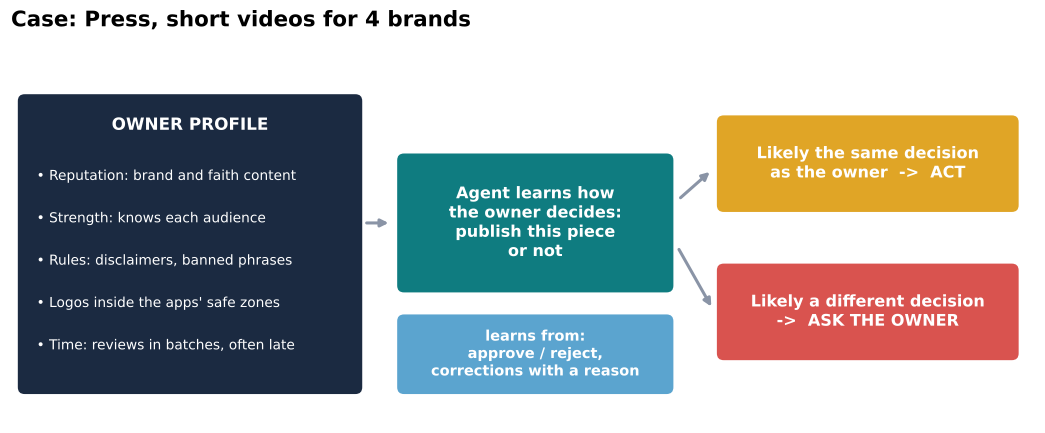

In [2]:
thesis_card("Press, short videos for 4 brands",
            ["Reputation: brand and faith content", "Strength: knows each audience",
             "Rules: disclaimers, banned phrases", "Logos inside the apps' safe zones",
             "Time: reviews in batches, often late"],
            "publish this piece\nor not",
            "approve / reject,\ncorrections with a reason")

## 1. Real data: what the accounts show

Two sources, both from the Press agent's own records (Zernio analytics and the weekly review of 14 Nov 2026). Post text and anyone's names are removed; only metrics remain.


In [3]:
import numpy as np
import pandas as pd

import io
DATA = {
    "press_posts_metrics.csv": """published,platform,brand,topic,language,views,likes,comments,shares,saves,follows,duration_s
2026-10-16,tiktok,analyst_channel,finance,en,29704,418,36,108,259,117,101.867
2026-10-19,facebook,analyst_channel,finance,en,26205,150,2,13,0,141,
2026-10-19,instagram,analyst_channel,finance,en,9596,53,2,43,60,0,45.0
2026-10-19,tiktok,analyst_channel,finance,en,2450,41,4,5,6,15,42.822
2026-10-30,instagram,analyst_channel,finance,en,1346,18,0,2,5,0,73.0
2026-11-10,youtube,tepeyac,religious,es,1280,107,6,0,0,0,34.0
2026-11-10,youtube,tepeyac,religious,es,1262,139,23,0,0,0,23.0
2026-11-15,youtube,tepeyac,religious,es,1077,119,3,0,0,0,24.0
2026-11-14,youtube,tepeyac,religious,es,1071,140,4,0,0,0,19.0
2026-11-08,youtube,tepeyac,religious,es,1048,33,0,0,0,0,13.0
2026-11-13,youtube,tepeyac,religious,es,1004,180,2,0,0,0,20.0
2026-10-18,tiktok,analyst_channel,finance,en,855,24,6,1,5,2,51.5
2026-11-14,youtube,tepeyac,religious,es,800,80,3,0,0,0,54.0
2026-11-12,youtube,tepeyac,religious,es,756,46,0,0,0,0,31.0
2026-10-18,tiktok,analyst_channel,finance,en,612,11,2,2,1,3,26.903
2026-11-08,facebook,tepeyac,religious,es,578,14,0,1,0,1,
2026-11-11,youtube,tepeyac,religious,es,521,31,0,0,0,0,20.0
2026-11-08,facebook,tepeyac,religious,es,475,5,0,0,0,0,
2026-10-20,tiktok,analyst_channel,finance,en,462,8,0,2,2,0,25.917
2026-11-08,youtube,tepeyac,religious,es,415,24,12,0,0,0,55.0
2026-10-18,instagram,analyst_channel,finance,en,400,2,0,1,1,0,51.0
2026-10-30,tiktok,analyst_channel,finance,en,321,10,0,0,3,3,73.886
2026-11-10,facebook,tepeyac,religious,es,319,7,0,0,0,0,
2026-10-16,tiktok,analyst_channel,finance,en,312,3,3,2,3,2,57.586
2026-11-10,youtube,tepeyac,religious,es,296,33,4,0,0,0,17.0
2026-10-18,facebook,analyst_channel,finance,en,296,1,0,0,0,1,
2026-10-16,tiktok,analyst_channel,finance,en,287,6,1,0,0,3,29.376
2026-11-10,facebook,tepeyac,religious,es,284,5,0,0,0,0,
2026-11-12,facebook,tepeyac,religious,es,272,2,0,0,0,0,
2026-10-30,tiktok,analyst_channel,finance,es,265,7,0,0,0,1,88.445
2026-11-13,facebook,tepeyac,religious,es,262,0,0,0,0,0,
2026-11-14,instagram,tepeyac,religious,es,260,19,5,3,2,0,18.0
2026-10-22,facebook,analyst_channel,finance,en,260,0,0,0,0,0,
2026-10-30,tiktok,analyst_channel,finance,en,257,5,0,1,2,1,28.067
2026-10-24,facebook,analyst_channel,finance,en,252,0,0,0,0,0,
2026-11-10,facebook,tepeyac,religious,es,247,5,0,0,0,1,
2026-10-22,tiktok,analyst_channel,finance,en,247,6,1,0,0,2,15.005
2026-11-08,tiktok,grabgo,grabgo,es,246,12,0,1,0,0,30.14
2026-10-18,instagram,analyst_channel,finance,en,245,3,0,0,0,0,28.0
2026-11-12,facebook,tepeyac,religious,es,241,1,0,0,0,0,
2026-11-10,instagram,tepeyac,religious,es,15,0,0,0,1,0,33.0
2026-11-14,instagram,tepeyac,religious,es,14,1,0,0,0,0,174.0
2026-11-11,facebook,grabgo,grabgo,en,14,0,0,0,0,0,
2026-11-11,instagram,tepeyac,religious,es,14,0,2,0,0,0,19.0
2026-10-30,youtube,analyst_channel,finance,en,14,0,1,0,0,0,160.0
2026-11-15,facebook,grabgo,grabgo,en,13,1,0,0,0,0,
2026-11-11,youtube,tepeyac,religious,es,12,0,0,0,0,0,86.0
2026-11-14,facebook,grabgo,grabgo,en,8,0,0,0,0,0,
2026-11-12,instagram,tepeyac,religious,es,8,0,0,0,0,0,78.0
2026-11-13,instagram,tepeyac,religious,es,6,0,0,0,0,0,76.0
2026-11-11,instagram,tepeyac,religious,es,6,0,0,0,0,0,85.0
2026-11-08,instagram,tepeyac,religious,es,6,0,0,0,0,0,
2026-11-04,youtube,grabgo,grabgo,es,6,0,0,0,0,0,215.0
2026-11-11,instagram,tepeyac,religious,es,3,0,0,0,0,0,97.0
2026-11-14,facebook,tepeyac,religious,es,2,0,0,0,0,0,
2026-11-13,facebook,grabgo,grabgo,en,2,0,0,0,0,0,
2026-11-04,youtube,grabgo,grabgo,en,2,0,0,0,0,0,183.0
2026-10-16,linkedin,analyst_channel,finance,en,2,1,0,0,0,0,
2026-11-10,facebook,tepeyac,finance,en,0,0,0,0,0,0,
2026-11-08,facebook,tepeyac,religious,es,0,0,0,0,0,0,
2026-11-08,facebook,tepeyac,finance,en,0,0,0,0,0,0,
2026-10-23,linkedin,analyst_channel,finance,en,0,0,0,0,0,0,
2026-10-21,linkedin,analyst_channel,finance,en,0,0,0,0,0,0,
2026-10-17,facebook,analyst_channel,finance,en,0,0,0,0,0,0,
2026-10-17,facebook,analyst_channel,finance,en,0,1,0,0,0,0,
2026-10-16,linkedin,analyst_channel,finance,en,0,1,0,0,0,0,
""",
    "grabgo_en_vs_es_tiktok.csv": """piece,persona,en_views,en_hold_2s_pct,en_hold_10s_pct,es_views,es_hold_2s_pct,es_hold_10s_pct,age_days
Next location,operator,197,23,4,,,,8.9
Airbnb little store,airbnb host,94,23,5,190,43,7,8.0
Operators new route,operator,93,22,6,206,51,14,7.0
Airbnb amenity ideas,airbnb host,91,25,8,246,52,25,6.0
Office you said no,operator,101,19,2,196,56,13,4.3
No app no cashier,shopper,45,13,0,145,40,7,4.0
Bot speaks your language,shopper,47,22,4,40,39,5,3.0
Machines never paid,operator,84,19,1,187,53,11,2.0
Stop turning down,operator,94,14,0,207,51,14,1.0
""",
}
def load(name):
    """The data travels inside the notebook, so it runs anywhere (Colab, Drive, GitHub)."""
    return pd.read_csv(io.StringIO(DATA[name]))

posts = load("press_posts_metrics.csv")            # the 40 most-viewed and 26 least-viewed of 186 posts
pairs = load("grabgo_en_vs_es_tiktok.csv")          # the same GrabGo piece in English and in Spanish
print(f"{len(posts)} posts · total views {posts.views.sum():,} · top post {posts.views.max():,} views · median {posts.views.median():.0f}")
pairs

66 posts · total views 87,233 · top post 29,704 views · median 258


,piece,persona,en_views,en_hold_2s_pct,en_hold_10s_pct,es_views,es_hold_2s_pct,es_hold_10s_pct,age_days
0,Next location,operator,197,23,4,NaN,NaN,NaN,8.9
1,Airbnb little store,airbnb host,94,23,5,190.0,43.0,7.0,8.0
2,Operators new route,operator,93,22,6,206.0,51.0,14.0,7.0
3,Airbnb amenity ideas,airbnb host,91,25,8,246.0,52.0,25.0,6.0
4,Office you said no,operator,101,19,2,196.0,56.0,13.0,4.3
5,No app no cashier,shopper,45,13,0,145.0,40.0,7.0,4.0
6,Bot speaks your language,shopper,47,22,4,40.0,39.0,5.0,3.0
7,Machines never paid,operator,84,19,1,187.0,53.0,11.0,2.0
8,Stop turning down,operator,94,14,0,207.0,51.0,14.0,1.0


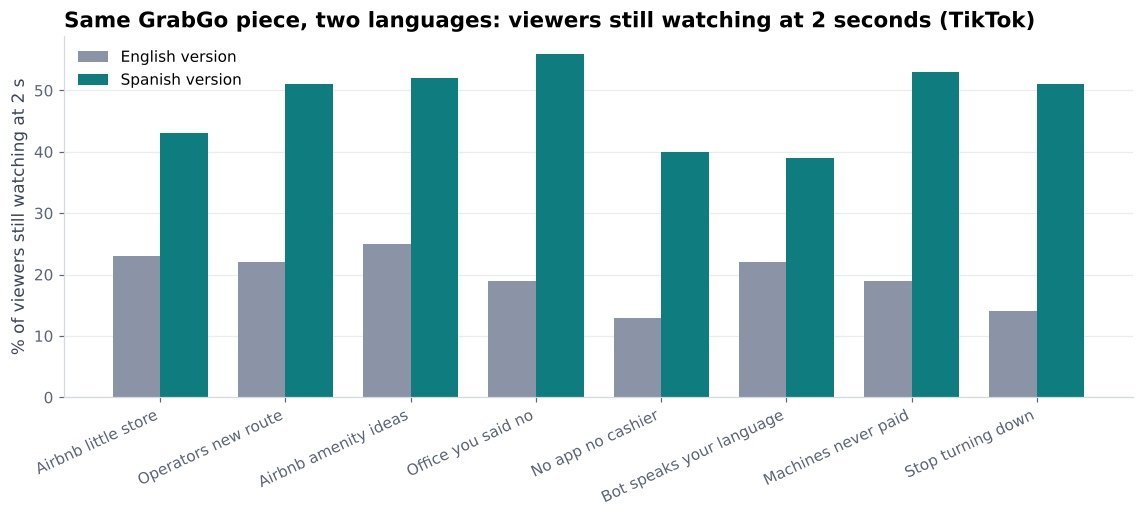

In [4]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
p = pairs.dropna()
x = np.arange(len(p)); w = 0.38
ax.bar(x - w / 2, p.en_hold_2s_pct, w, color=PALETTE["grey"], label="English version")
ax.bar(x + w / 2, p.es_hold_2s_pct, w, color=PALETTE["teal"], label="Spanish version")
ax.set_xticks(x); ax.set_xticklabels(p.piece, rotation=25, ha="right"); ax.grid(axis="x", visible=False)
ax.set_title("Same GrabGo piece, two languages: viewers still watching at 2 seconds (TikTok)")
ax.set_ylabel("% of viewers still watching at 2 s"); ax.legend()
plt.tight_layout(); plt.show()

**What the real data says about the owner's decisions.** The Spanish version keeps about twice as many viewers in the first 2 seconds in 8 of 8 pairs. The agent proposed on 14 Nov to write each script in Spanish first, but the proposal, like the white-paper update proposed on 31 Oct, was still **waiting for my approval**. During the same weeks the Equilibra channel published nothing new because its next piece was not approved, and Facebook follower growth fell from +26 in a week to +4. The agent was right and blocked; the bottleneck was the approval.

## 2. Literature

| Research line | Key result | What it gives this case |
|---|---|---|
| RL from human preferences [1] | Agents can learn complex goals from human comparisons of behaviour, needing feedback on a small fraction of interactions | Approvals are learnable feedback, but each yes/no carries little information |
| Feedback on explanations [2] | Penalizing a model for relying on features a human marks as wrong ("right for the right reasons") teaches it the intended rule with far less data | A correction that names *why* a piece is wrong is a different, richer signal than a rejection |
| Personalized alignment [3, 4] | Preferences are individual; retrieving a user's own history improves personalized outputs (LaMP) | The owner's past decisions are the profile; the question is which form of feedback fills it fastest |
| Generative agents of real people [5] | Interview-based context lets agents reproduce individuals far better than demographic descriptions | Rich statements of reasons beat bare labels |

**Gap.** Personalization benchmarks use one form of feedback at a time. For an owner with little time, the practical question is the *exchange rate*: how many yes/no approvals is one correction with a reason worth?


## 3. Experiment 1: corrections with a reason versus yes/no approvals

Each piece of content is described by 12 attributes (language, hook with a number, a chart, a meme format, a finance disclaimer, a banned phrase, logo inside the safe zone, a claim to be "official", a price claim, a call to action, length, topic). The owner's decision has two layers, as in real life:

- **Hard rules** (any violation means "no"): a banned phrase, a finance piece without its disclaimer, a logo outside the safe zone, a claim to be an official site.
- **Taste** (a soft preference): likes charts and numbers in the hook, dislikes long pieces, prefers Spanish for GrabGo.

Two agents see the same pieces and ask the owner about each one during training:

1. **Yes/no**: learns only whether the owner approved.
2. **Correction with a reason**: when the owner rejects a piece for a rule, he names the rule ("banned phrase"); the agent turns it into a hard constraint. Taste is still learned from yes/no.

**Error:** on 2,000 new pieces, the share where the agent's decision differs from the owner's, and the share of **pieces the agent would publish that the owner would reject** (the dangerous error).


In [5]:
from sklearn.linear_model import LogisticRegression

ATTR = ["spanish", "number_hook", "chart", "meme", "disclaimer", "banned_phrase", "logo_safe",
        "claims_official", "price_claim", "cta", "long", "finance"]
RULES = {"banned_phrase": lambda a: a["banned_phrase"] == 1, "missing_disclaimer": lambda a: a["finance"] == 1 and a["disclaimer"] == 0,
         "logo_outside_safe_zone": lambda a: a["logo_safe"] == 0, "claims_official": lambda a: a["claims_official"] == 1}
TASTE = dict(spanish=0.8, number_hook=0.9, chart=1.1, meme=0.2, cta=0.3, long=-1.2, price_claim=-0.4)

def make_piece(rng):
    a = {k: int(rng.random() < p) for k, p in zip(ATTR, [0.5, 0.4, 0.3, 0.4, 0.7, 0.08, 0.85, 0.05, 0.2, 0.6, 0.3, 0.5])}
    return a

def owner_decides(a, rng):
    broken = [r for r, f in RULES.items() if f(a)]
    if broken: return 0, broken[0]
    z = sum(TASTE.get(k, 0) * v for k, v in a.items()) - 0.6 + rng.normal(0, 0.5)
    return int(z > 0), None

def vec(a): return np.array([a[k] for k in ATTR], float)

def train_and_test(n_feedback, with_reasons, seed):
    rng = np.random.default_rng(seed); X, y, learned_rules = [], [], set()
    for _ in range(n_feedback):
        a = make_piece(rng); dec, reason = owner_decides(a, rng)
        if with_reasons and reason: learned_rules.add(reason)
        if with_reasons and reason: continue                     # rule rejections teach the rule, not the taste
        X.append(vec(a)); y.append(dec)
    model = LogisticRegression(C=2.0).fit(X, y) if len(set(y)) == 2 else None
    test_rng = np.random.default_rng(10_000 + seed); errs = danger = 0; N = 2000
    for _ in range(N):
        a = make_piece(test_rng); truth, _ = owner_decides(a, test_rng)
        if any(RULES[r](a) for r in learned_rules): pred = 0
        else: pred = int(model.predict_proba([vec(a)])[0, 1] > 0.5) if model else 1
        errs += pred != truth; danger += (pred == 1 and truth == 0)
    return errs / N, danger / N

grid = [10, 20, 40, 80, 160, 320, 640]
curve = []
for n in grid:
    for wr in (False, True):
        e = np.array([train_and_test(n, wr, s) for s in range(6)])
        curve.append(dict(owner_reviews=n, feedback="correction with a reason" if wr else "yes/no only",
                          disagreement_pct=100 * e[:, 0].mean(), would_publish_rejected_pct=100 * e[:, 1].mean()))
curve = pd.DataFrame(curve)
curve.pivot(index="owner_reviews", columns="feedback", values="disagreement_pct").round(1)

feedback,correction with a reason,yes/no only
owner_reviews,,
10,34.7,39.0
20,23.5,30.7
40,16.9,23.9
80,11.2,19.2
160,9.4,16.3
320,8.6,14.4
640,8.1,13.8


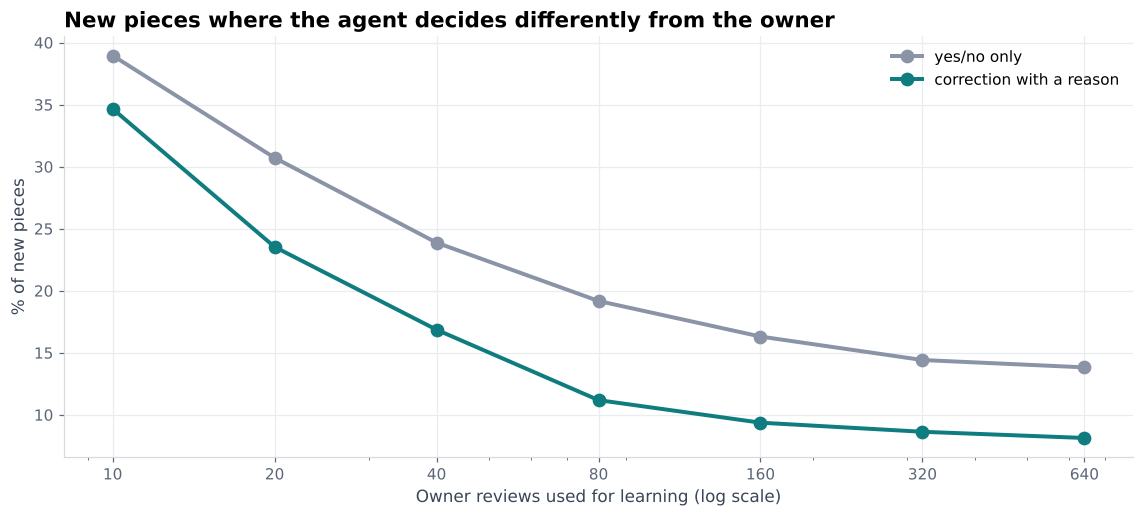

With corrections, 40 reviews reach 16.9% disagreement. Yes/no needs 160 reviews to do the same.


In [6]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
for fb, c in [("yes/no only", PALETTE["grey"]), ("correction with a reason", PALETTE["teal"])]:
    d = curve[curve.feedback == fb]
    ax.plot(d.owner_reviews, d.disagreement_pct, "-o", color=c, lw=2.6, ms=8, label=fb)
ax.set_xscale("log"); ax.set_xticks(grid); ax.set_xticklabels(grid)
ax.set_title("New pieces where the agent decides differently from the owner")
ax.set_xlabel("Owner reviews used for learning (log scale)"); ax.set_ylabel("% of new pieces"); ax.legend()
plt.tight_layout(); plt.show()

# Exchange rate: how many yes/no reviews reach the error that corrections reach with 40 reviews?
target = curve[(curve.feedback == "correction with a reason") & (curve.owner_reviews == 40)].disagreement_pct.item()
yn = curve[curve.feedback == "yes/no only"].set_index("owner_reviews").disagreement_pct
reach = yn[yn <= target]
print(f"With corrections, 40 reviews reach {target:.1f}% disagreement. Yes/no needs "
      f"{reach.index.min() if len(reach) else 'more than 640'} reviews to do the same.")

## 4. Experiment 2: what waiting for approval costs

Market-reactive pieces (a meme about today's Bitcoin move) lose value fast; evergreen pieces (how to pray the Rosary) do not. Using the real view distribution of the accounts (the posts above), each proposed piece has a potential reach drawn from that distribution and a value half-life of **2 days** if reactive, **30 days** if evergreen (assumptions). Three approval policies:

1. **Owner reviews everything in a weekly batch** (what happened in practice: proposals waited a week or more).
2. **Owner reviews everything within 1 day**.
3. **Agent publishes alone** when it predicts the owner's approval with high confidence and no hard rule is at risk (the "correction" agent from Experiment 1 after 160 reviews); everything else waits for the weekly batch.


In [7]:
rng = np.random.default_rng(3)
reach_pool = posts.views[posts.views > 0].to_numpy()
corr_rules = set(RULES)                                   # the correction agent has learned the four rules
X, y = [], []
for _ in range(160):
    a = make_piece(rng); d, reason = owner_decides(a, rng)
    if reason is None: X.append(vec(a)); y.append(d)
taste_model = LogisticRegression(C=2.0).fit(X, y)

def simulate(policy, n=3000, seed=5):
    rng = np.random.default_rng(seed); kept = lost = wrong = 0.0; auto = 0
    for _ in range(n):
        a = make_piece(rng); truth, _ = owner_decides(a, rng)
        reach = rng.choice(reach_pool); half = 2 if rng.random() < 0.5 else 30
        if policy == "weekly batch": delay = rng.uniform(0, 7) + 1
        elif policy == "owner within 1 day": delay = rng.uniform(0, 1)
        else:
            rule_risk = any(RULES[r](a) for r in corr_rules)
            p = taste_model.predict_proba([vec(a)])[0, 1]
            if not rule_risk and p > 0.9:
                auto += 1; delay = 0
                if truth == 0: wrong += 1; continue          # published something the owner would reject
            else:
                delay = rng.uniform(0, 7) + 1
        if truth == 1:
            v = reach * 0.5 ** (delay / half); kept += v; lost += reach - v
    return dict(policy=policy, views_kept=kept, views_lost_to_waiting=lost,
                pieces_owner_would_reject_published=wrong, published_without_review_pct=100 * auto / n)

wait = pd.DataFrame([simulate(p) for p in ["weekly batch", "owner within 1 day", "agent publishes when confident"]]).set_index("policy")
wait["share_of_reach_lost_pct"] = 100 * wait.views_lost_to_waiting / (wait.views_kept + wait.views_lost_to_waiting)
wait.round(1)

,views_kept,views_lost_to_waiting,pieces_owner_would_reject_published,published_without_review_pct,share_of_reach_lost_pct
policy,,,,,
weekly batch,1059299.9,581491.1,0.0,0.0,35.4
owner within 1 day,1525870.0,114921.0,0.0,0.0,7.0
agent publishes when confident,1638422.5,233852.5,13.0,19.8,12.5


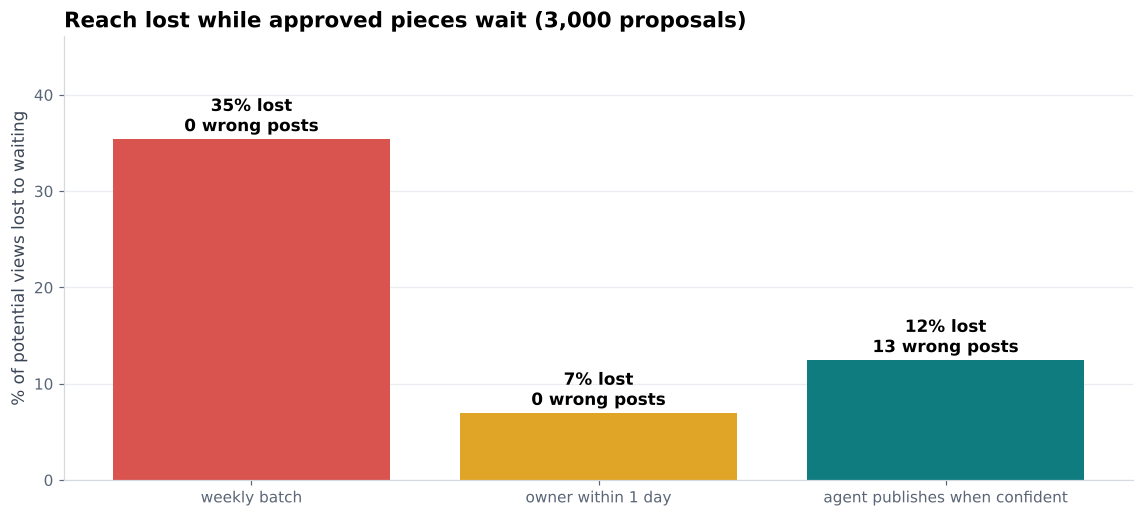

In [8]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
cols = [PALETTE["coral"], PALETTE["gold"], PALETTE["teal"]]
bars = ax.bar(wait.index, wait.share_of_reach_lost_pct, color=cols); ax.grid(axis="x", visible=False)
for b, v, w_ in zip(bars, wait.share_of_reach_lost_pct, wait.pieces_owner_would_reject_published):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.0f}% lost\n{int(w_)} wrong posts", ha="center", fontsize=11, fontweight="bold")
ax.set_ylim(0, wait.share_of_reach_lost_pct.max() * 1.3)
ax.set_title("Reach lost while approved pieces wait (3,000 proposals)")
ax.set_ylabel("% of potential views lost to waiting")
plt.tight_layout(); plt.show()

## 5. Findings

> **Key finding 1.** A correction that names the broken rule teaches the owner's criteria about **four times faster** than a yes/no approval: with corrections, 40 reviews bring disagreement with the owner to about 17%; yes/no approvals need about 160 reviews to get there, and the gap persists even at 640 reviews (8% vs 14%). For an owner with little time, **asking for the reason** is the cheapest way to transfer his profile.
>
> **Key finding 2.** With weekly batch reviews, about **35% of the potential reach** of approved pieces is lost to waiting, because reactive pieces age in days. An agent that publishes alone only when it is confident and no rule is at risk (about 1 piece in 5) cuts the loss to about **12%**, at the cost of 13 published pieces out of 3,000 that the owner would have rejected. That trade-off is the owner's to decide, and it is exactly the decision the thesis wants the agent to learn.
>
> **Key finding 3 (real data).** In the real accounts the agent's proposal (Spanish first for GrabGo) was supported by 8 of 8 pairs and still waited for approval, while the Equilibra channel stalled for two weeks for lack of an approved piece. The bottleneck was not the agent's quality but the owner's review time.

**Limitations.** Simulated pieces and owner; the real-post sample is the top 40 and bottom 26 of 186 posts, so it overstates the tail; the half-lives are assumptions.

## 6. Thesis questions

1. How should an LLM agent turn a free-text correction ("no uses esa frase") into a reusable constraint across brands, and know when the correction is brand-specific?
2. What is the optimal moment to ask for a review, balancing the owner's time against content aging?
3. Can the agent detect that the owner's taste is drifting (for example, after a viral post) and ask again about rules it considered settled?

## References

1. Christiano, P., Leike, J., Brown, T., Martic, M., Legg, S., & Amodei, D. (2017). *Deep reinforcement learning from human preferences.* NeurIPS 2017.
2. Ross, A. S., Hughes, M. C., & Doshi-Velez, F. (2017). *Right for the Right Reasons: Training Differentiable Models by Constraining their Explanations.* IJCAI 2017.
3. Salemi, A., Mysore, S., Bendersky, M., & Zamani, H. (2024). *LaMP: When Large Language Models Meet Personalization.* ACL 2024. arXiv:2304.11406.
4. Poddar, S., et al. (2024). *Personalizing RLHF with Variational Preference Learning.* NeurIPS 2024.
5. Park, J. S., et al. (2024). *Generative Agent Simulations of 1,000 People.* arXiv:2411.10109.
